Given integers a₁, …, aₙ, count pairs satisfying i < j and aᵢ > 2aⱼ.

## Brute Force Cross Period Pair Counting

In [1]:
# Brute force
def CrossPeriodPairs(A):
    cross_counts = 0
    comparisons = 0
    for i in range(len(A) - 1):
        for j in range(i + 1, len(A)):
            comparisons += 1
            if A[i] > 2 * A[j]:
                cross_counts += 1
    return cross_counts, comparisons


## Modified Merge Sort Code

In [2]:
def merge_count_pairs(B: list[int], C: list[int], count: int, comparisons: int, A: list[int]) -> tuple[int, int]:
    p = len(B)
    q = len(C)

    j = 0
    for i in range(p):
        while j < q:
            comparisons += 1
            if B[i] > 2 * C[j]:
                j += 1
            else:
                break
        count += j

    i = 0
    j = 0
    k = 0
    while i < p and j < q:
        comparisons += 1
        if B[i] <= C[j]:
            A[k] = B[i]
            i += 1
        else:
            A[k] = C[j]
            j += 1
        k += 1

    if i == p:
        while j < q:
            A[k] = C[j]
            j += 1
            k += 1
    else:
        while i < p:
            A[k] = B[i]
            i += 1
            k += 1

    return count, comparisons


def merge_sort(A: list[int]) -> tuple[int, int]:
    n = len(A)
    if n > 1:
        mid = n // 2
        B = A[:mid]
        C = A[mid:]

        count_b, comp_b = merge_sort(B)
        count_c, comp_c = merge_sort(C)
        return merge_count_pairs(B, C, count_b + count_c, comp_b + comp_c, A)
    else:
        return 0, 0

## Testing

In [3]:
randomised_integers = [9, 4, 15, 2, 7, 1]
positive_integers = [1, 2, 7, 3, 14, 28, 2]
negative_integers = [-2, -5, -1, -4, -3]
mixed_sign_integers = [5, -3, 2, -1, 0, -4]
sorted_inputs = [1, 3, 5, 8, 12, 20]
duplicate_heavy_inputs = [5, 5, 2, 2, 5, 2]
empty_array = []
single_element_array = [5]

In [4]:
import pandas as pd

tests = [
    ("Empty Array", empty_array, 0),
    ("Single-Element Array", single_element_array, 0),
    ("Randomised Integers", randomised_integers, 8),
    ("Positive Integers", positive_integers, 4),
    ("Negative Integers", negative_integers, 8),
    ("Mixed-Sign Integers", mixed_sign_integers, 11),
    ("Sorted Inputs", sorted_inputs, 0),
    ("Duplicate-Heavy Inputs", duplicate_heavy_inputs, 7),
]

rows = []
for name, arr, manual_res in tests:
    bf_res, _ = CrossPeriodPairs(arr)
    ms_res, _ = merge_sort(arr.copy())
    
    rows.append({
        "Test Case": name,
        "Array": arr,
        "Manually Verified Result": manual_res,
        "Brute Force Result": bf_res,
        "Modified MergeSort Result": ms_res,
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))

             Test Case                   Array  Manually Verified Result  Brute Force Result  Modified MergeSort Result
           Empty Array                      []                         0                   0                          0
  Single-Element Array                     [5]                         0                   0                          0
   Randomised Integers     [9, 4, 15, 2, 7, 1]                         8                   8                          8
     Positive Integers [1, 2, 7, 3, 14, 28, 2]                         4                   4                          4
     Negative Integers    [-2, -5, -1, -4, -3]                         8                   8                          8
   Mixed-Sign Integers   [5, -3, 2, -1, 0, -4]                        11                  11                         11
         Sorted Inputs    [1, 3, 5, 8, 12, 20]                         0                   0                          0
Duplicate-Heavy Inputs      [5, 5, 2, 2,

# Additional Testing and Experimentation

In [5]:
# The tests below test the algorithm's behaviour on inputs of sizes 50-300 in increments of 50
import random

random.seed(42)

sizes = [1000, 2000, 4000, 8000, 16000]


# Functions to generate random numbers to satisfy the different crtieria, of elements to experiment on the algorithm
def regular(n):
    return [random.randint(-100, 100) for _ in range(n)]


def negative(n):
    return [random.randint(-100, -1) for _ in range(n)]


def decreasing(n):
    return sorted(random.sample(range(-10 * n, 10 * n), n), reverse=True)


def non_decreasing(n):
    return sorted(random.randint(-100, 100) for _ in range(n))


generators = {
    "regular": regular,
    "negative": negative,
    "decreasing": decreasing,
    "non_decreasing": non_decreasing,
}

In [6]:
import random
import time
arrays = {name: {n: gen(n) for n in sizes} for name, gen in generators.items()}

# Store experiment results
results = {}

for name, by_size in arrays.items():
    for n, a in by_size.items():
        # Measuring the time, pairs, and comparisons counted for mergesort
        start = time.perf_counter()
        ms_pairs, ms_comparisons = merge_sort(a.copy())
        ms_time = time.perf_counter() - start

        # Measuring the time, pairs, and comparisons counted for the bruteforce approach
        start = time.perf_counter()
        cross_pairs, cross_comparisons = CrossPeriodPairs(a.copy())
        cross_time = time.perf_counter() - start

        # Storing the measurements
        results[(name, n)] = {
            "ms_pairs": ms_pairs,
            "ms_comparisons": ms_comparisons,
            "ms_time": ms_time,
            "cross_pairs": cross_pairs,
            "cross_comparisons": cross_comparisons,
            "cross_time": cross_time,
        }


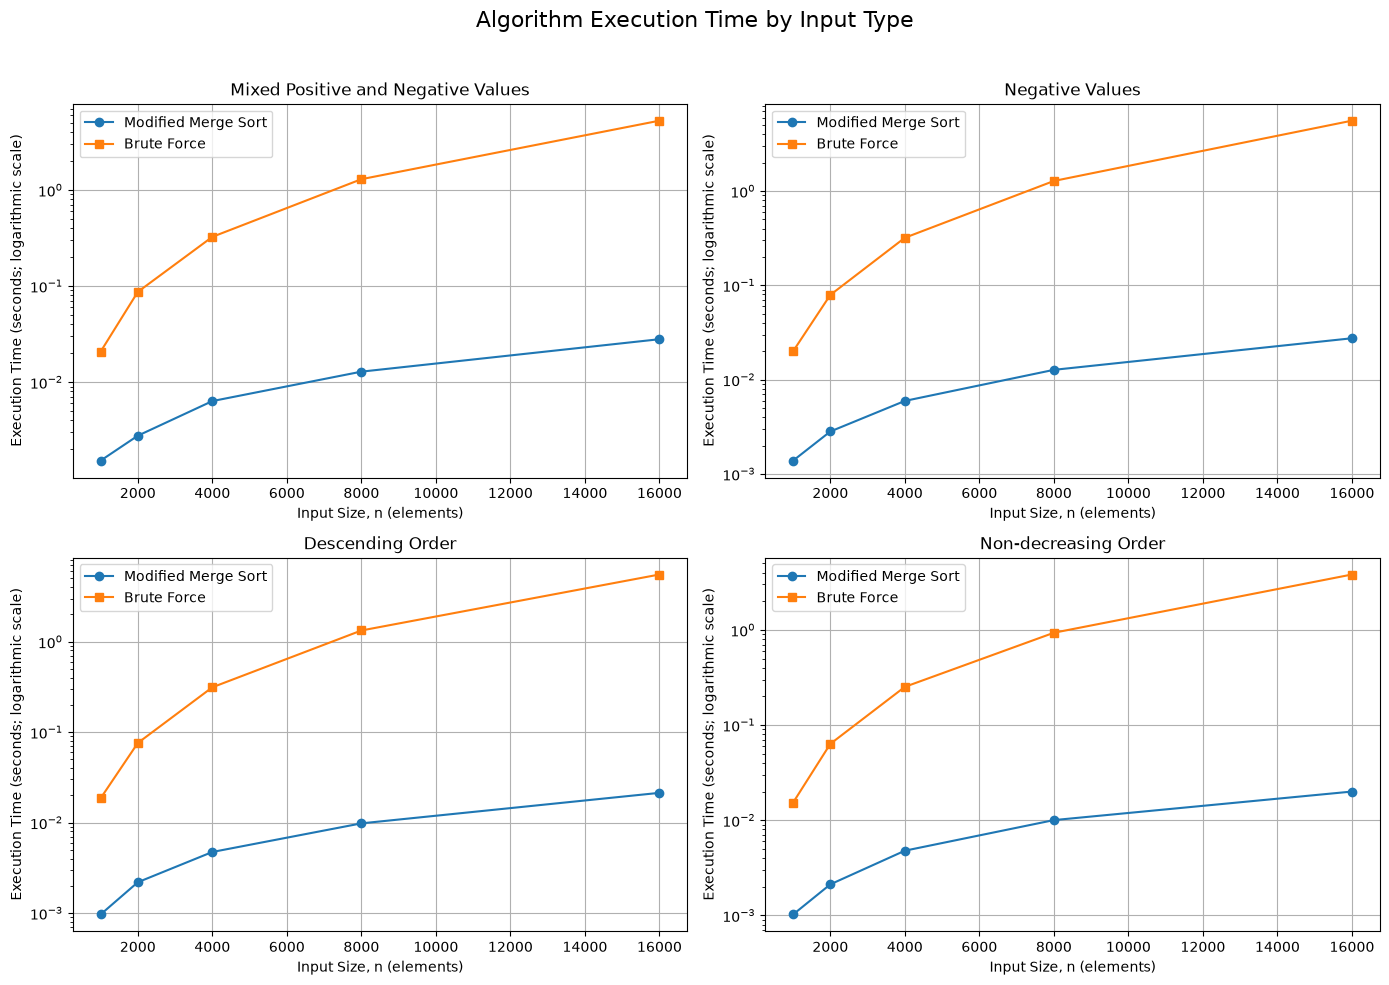

In [7]:
import matplotlib.pyplot as plt
array_types = list(generators.keys())
array_labels = {
    "regular": "Mixed Positive and Negative Values",
    "negative": "Negative Values",
    "decreasing": "Descending Order",
    "non_decreasing": "Non-decreasing Order",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, name in zip(axes.flatten(), array_types):
    ms_times = [results[(name, n)]["ms_time"] for n in sizes]

    cross_times = [results[(name, n)]["cross_time"] for n in sizes]

    ax.plot(sizes, ms_times, marker="o", label="Modified Merge Sort")
    ax.plot(sizes, cross_times, marker="s", label="Brute Force")

    ax.set_title(array_labels[name])
    ax.set_xlabel("Input Size, n (elements)")
    ax.set_yscale("log", base=10)
    ax.set_ylabel("Execution Time (seconds; logarithmic scale)")
    ax.legend()
    ax.grid(True)

fig.suptitle("Algorithm Execution Time by Input Type", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


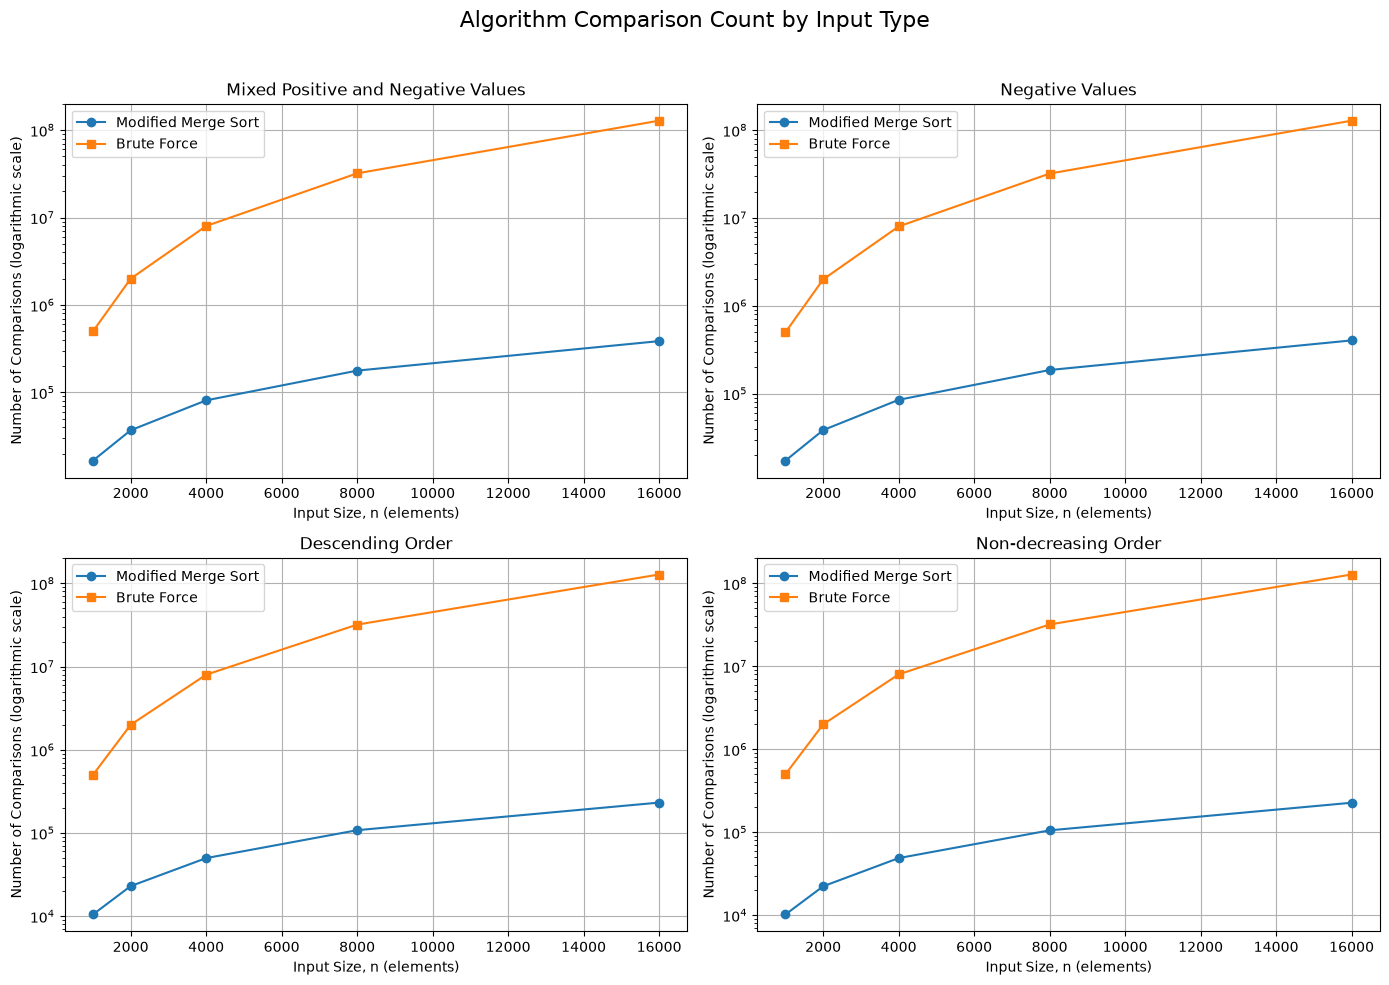

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, name in zip(axes.flatten(), array_types):
    ms_comparisons = [results[(name, n)]["ms_comparisons"] for n in sizes]

    cross_comparisons = [results[(name, n)]["cross_comparisons"] for n in sizes]

    ax.plot(sizes, ms_comparisons, marker="o", label="Modified Merge Sort")
    ax.plot(sizes, cross_comparisons, marker="s", label="Brute Force")

    ax.set_title(array_labels[name])
    ax.set_xlabel("Input Size, n (elements)")
    ax.set_yscale("log", base=10)
    ax.set_ylabel("Number of Comparisons (logarithmic scale)")
    ax.legend()
    ax.grid(True)

fig.suptitle("Algorithm Comparison Count by Input Type", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()